<a href="https://colab.research.google.com/github/hgsrushthi-peachy/ai-tools-mini-project/blob/main/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

data = {
    "Area": [800, 1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 1100, 1600],
    "Bedrooms": [1, 2, 2, 3, 3, 4, 4, 4, 5, 5, 2, 3],
    "Age": [15, 10, 8, 5, 6, 3, 4, 2, 1, 1, 12, 7],
    "Price": [30, 42, 50, 65, 78, 90, 98, 112, 128, 138, 46, 70]
}
df = pd.DataFrame(data)
print(df)

    Area  Bedrooms  Age  Price
0    800         1   15     30
1   1000         2   10     42
2   1200         2    8     50
3   1500         3    5     65
4   1800         3    6     78
5   2000         4    3     90
6   2200         4    4     98
7   2500         4    2    112
8   2800         5    1    128
9   3000         5    1    138
10  1100         2   12     46
11  1600         3    7     70


In [2]:
X = df[["Area", "Bedrooms", "Age"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained!")

Model trained!


In [6]:
y_pred = model.predict(X_test)
print(pd.DataFrame({"Actual": y_test, "Predicted": y_pred.round(2)}))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

    Actual  Predicted
10      46      46.16
9      138     136.30
0       30      30.66
MAE: 0.8396483407627807
R2 Score: 0.9995055958466286


In [7]:
new_house = pd.DataFrame({"Area": [1750], "Bedrooms": [3], "Age": [5]})
print("Predicted price (lakhs):", round(model.predict(new_house)[0], 2))

Predicted price (lakhs): 76.32


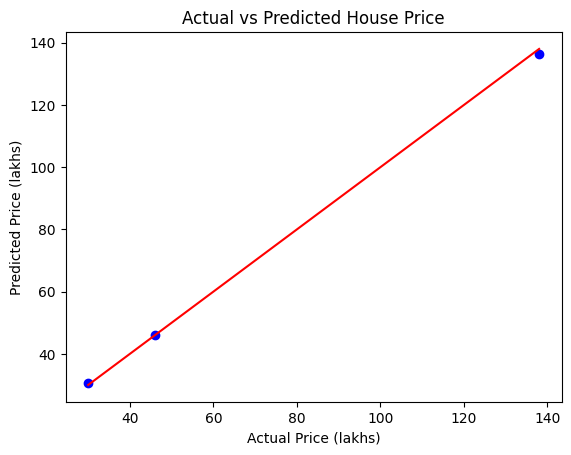

In [8]:
plt.scatter(y_test, y_pred, color="blue")
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.title("Actual vs Predicted House Price")
plt.xlabel("Actual Price (lakhs)")
plt.ylabel("Predicted Price (lakhs)")
plt.show()